<a href="https://colab.research.google.com/github/ahmed-mannan/PGCB-Bangladesh-Hourly-Grid-Demand-Forecasting/blob/main/CSE475_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Project Overview: PGCB Bangladesh Hourly Grid Demand Forecasting

This project focuses on predicting short-term hourly electricity demand for the Power Grid Company of Bangladesh (PGCB) using historical power generation data combined with local environmental and temporal features.

* **Dataset Source:** PGCB Hourly Generation Dataset (Bangladesh), hosted on the UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)
* **Objective:** Develop, evaluate, and fine-tune supervised machine learning models to forecast grid load demand accurately, helping optimize power dispatch, minimize generation costs, and reduce grid failure risks during peak hours.
* **Pipeline Structure:** Data Cleaning & Exploratory Data Analysis (EDA) $\rightarrow$ Feature Engineering & Spearman Correlation Analysis $\rightarrow$ Time-Series Splitting $\rightarrow$ Multi-Model Benchmarking $\rightarrow$ LightGBM Hyperparameter Fine-Tuning $\rightarrow$ Model Interpretability (SHAP & Feature Importance) $\rightarrow$ Diagnostic Error Evaluation.

# 1: Setup and EDA

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests #for weather data
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error, max_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from scipy.stats import randint, uniform

import shap

# Set display options for readable outputs
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully.\n")

Libraries imported successfully.



## Load dataset

In [ ]:
#dataset URL : https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)

file_path = 'PGCB_date_power_demand.xlsx'
df = pd.read_excel(file_path)

print("--- Dataset Shape ---")
print(df.shape)

--- Dataset Shape ---
(92650, 15)


## Basic EDA & Dataset Inspection

In [ ]:
# Display first 5 rows
print("--- First 5 Rows ---")
print(df.head())
print("\n" + "="*50 + "\n")

# Display dataset metadata and data types
print("--- Data Info & Types ---")
df.info()
print("\n" + "="*50 + "\n")

# Check for missing (null) values per column
print("--- Missing Values Count ---")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0])
print("\n" + "="*50 + "\n")

# Check for duplicate rows
print("--- Duplicate Rows Count ---")
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}\n")
print("\n" + "="*50 + "\n")

# Summary statistics (describe) with skewness
print("--- Summary Statistics (describe) & Skewness ---")
desc_df = df.describe().T
desc_df['skewness'] = df.skew(numeric_only=True)
print(desc_df)

--- First 5 Rows ---
             datetime  generation_mw  demand_mw  load_shedding   gas  liquid_fuel  coal  hydro  solar  wind  india_bheramara_hvdc  india_tripura  india_adani  nepal       remarks
0 2015-04-19 22:00:00         6323.0       6323              0     0            0     0      0    NaN   NaN                     0              0          NaN    NaN           NaN
1 2015-04-19 21:00:00         6667.0       6667              0     0            0     0      0    NaN   NaN                     0              0          NaN    NaN           NaN
2 2015-04-19 19:00:00         6897.0       6897              0  4415         1836   161     41    NaN   NaN                   444              0          NaN    NaN           NaN
3 2015-04-19 18:30:00         6933.0       6933              0  4423         1862   159     45    NaN   NaN                   444              0          NaN    NaN  Evening_Peak
4 2015-04-19 18:00:00         6874.0       6874              0  4319         1892   

## Historical Demand Trend (2015 to Present)

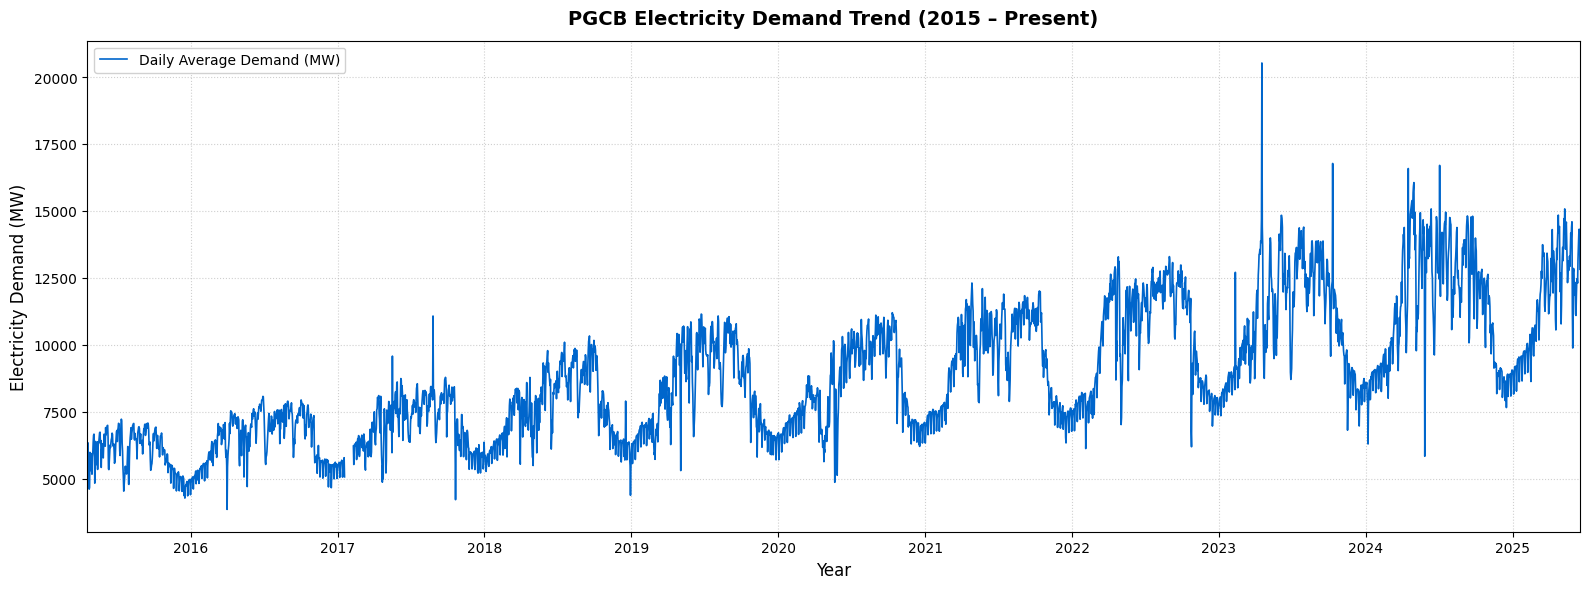

In [ ]:
# 1. Ensure datetime is in proper datetime format
if not pd.api.types.is_datetime64_any_dtype(df['datetime']):
    df['datetime'] = pd.to_datetime(df['datetime'])

# 2. Resample to daily average for a smooth, high-level historical trend
df_daily = df.set_index('datetime')['demand_mw'].resample('D').mean().reset_index()

# 3. Plot Full Historical Demand Trend
plt.figure(figsize=(16, 6))
plt.plot(df_daily['datetime'], df_daily['demand_mw'], color='#0066CC', linewidth=1.2, label='Daily Average Demand (MW)')

# Formatting plot aesthetics
plt.title("PGCB Electricity Demand Trend (2015 – Present)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Electricity Demand (MW)", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# Format X-axis date bounds
plt.xlim(df_daily['datetime'].min(), df_daily['datetime'].max())

plt.tight_layout()
plt.show()

## Day Peak Average Demand Month-wise

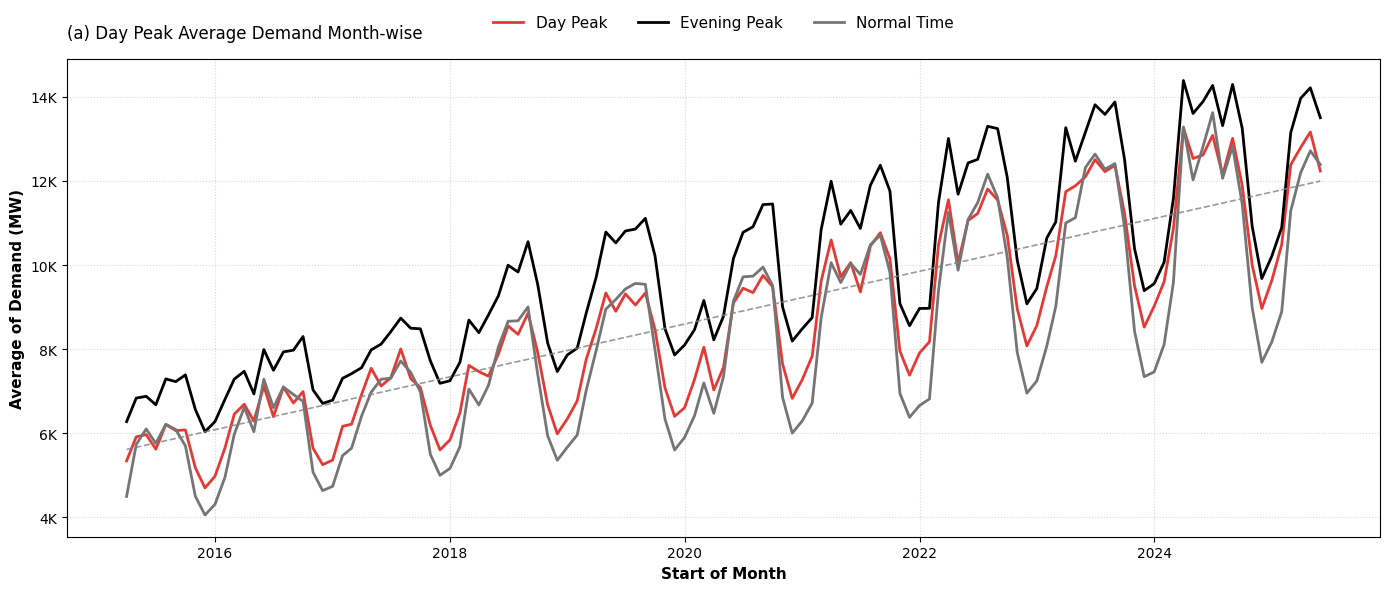

In [ ]:
# 1. Feature Extraction for Categorization
df_fig3a = df.copy()

# Classify time of day (Typical PGCB windows)
# Day Peak: 09:00 - 17:00 | Evening Peak: 17:00 - 23:00 | Normal Time: Night / Early Morning
def categorize_time_of_day(hour):
    if 9 <= hour < 17:
        return 'Day Peak'
    elif 17 <= hour < 23:
        return 'Evening Peak'
    else:
        return 'Normal Time'

df_fig3a['time_category'] = df_fig3a['datetime'].dt.hour.apply(categorize_time_of_day)

# Monthly Period for Grouping
df_fig3a['year_month'] = df_fig3a['datetime'].dt.to_period('M')

# Calculate monthly average demand per category
monthly_peaks = df_fig3a.groupby(['year_month', 'time_category'])['demand_mw'].mean().unstack()

# Convert PeriodIndex to Datetime for smooth plotting
x_dates = monthly_peaks.index.to_timestamp()

# 2. Create Single Plot
plt.figure(figsize=(14, 6))

# Plot Lines matching target image colors
plt.plot(x_dates, monthly_peaks['Day Peak'], label='Day Peak', color='#E53935', linewidth=2)
plt.plot(x_dates, monthly_peaks['Evening Peak'], label='Evening Peak', color='black', linewidth=2)
plt.plot(x_dates, monthly_peaks['Normal Time'], label='Normal Time', color='#757575', linewidth=2)

# Linear Trend Line (Overall Average)
overall_monthly = df_fig3a.groupby('year_month')['demand_mw'].mean()
x_numeric = np.arange(len(x_dates))
z = np.polyfit(x_numeric, overall_monthly.values, 1)
p = np.poly1d(z)
plt.plot(x_dates, p(x_numeric), color='gray', linestyle='--', linewidth=1.2, alpha=0.8)

# 3. Formatting & Styling
plt.title("(a) Day Peak Average Demand Month-wise", fontsize=12, pad=15, loc='left')
plt.xlabel("Start of Month", fontsize=11, fontweight='bold')
plt.ylabel("Average of Demand (MW)", fontsize=11, fontweight='bold')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.12), ncol=3, frameon=False, fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)

# Format Y-axis with 'K' suffix (e.g., 4K, 6K, 8K)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{int(y/1000)}K' if y >= 1000 else f'{int(y)}'))

plt.tight_layout()
plt.show()

## Summer vs. Winter Demand Profile Comparison

This cell picks a full representative year (e.g., 2023) and compares average hourly demand profiles across a peak Summer month (May) and a peak Winter month (January).

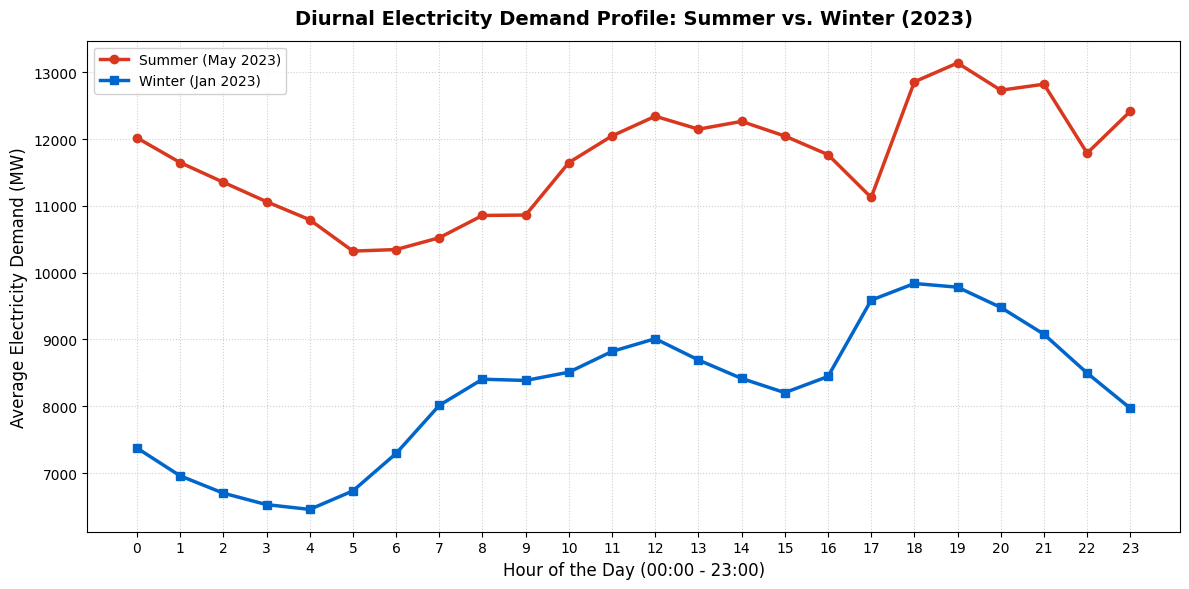

In [ ]:
# 1. Filter for a representative year (2023) and isolate Summer vs Winter months
df_2023 = df[df['datetime'].dt.year == 2023].copy()

# Summer (May) vs Winter (January)
df_summer = df_2023[df_2023['datetime'].dt.month == 5]
df_winter = df_2023[df_2023['datetime'].dt.month == 1]

# 2. Calculate average demand by hour of the day (0-23)
summer_hourly = df_summer.groupby(df_summer['datetime'].dt.hour)['demand_mw'].mean()
winter_hourly = df_winter.groupby(df_winter['datetime'].dt.hour)['demand_mw'].mean()

# 3. Plot Hourly Profiles
plt.figure(figsize=(12, 6))

plt.plot(summer_hourly.index, summer_hourly.values, color='#D9381E', linewidth=2.5, marker='o', label='Summer (May 2023)')
plt.plot(winter_hourly.index, winter_hourly.values, color='#0066CC', linewidth=2.5, marker='s', label='Winter (Jan 2023)')

# Formatting plot aesthetics
plt.title("Diurnal Electricity Demand Profile: Summer vs. Winter (2023)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Hour of the Day (00:00 - 23:00)", fontsize=12)
plt.ylabel("Average Electricity Demand (MW)", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

The summer load profile is consistently higher than the winter profile across all 24 hours, driven by heavy residential and commercial cooling loads. While both seasons exhibit a similar diurnal double-peak shape (Day Peak and Evening Peak), summer peak demand exceeds winter peak demand by approximately 3,000–4,000 MW.

## COVID-19 Lockdown vs. Normal Phase Demand Comparison

This cell compares daily average demand during the strict initial nationwide lockdown window (March–May 2020) against the exact same calendar period in a normal baseline year (March–May 2022).

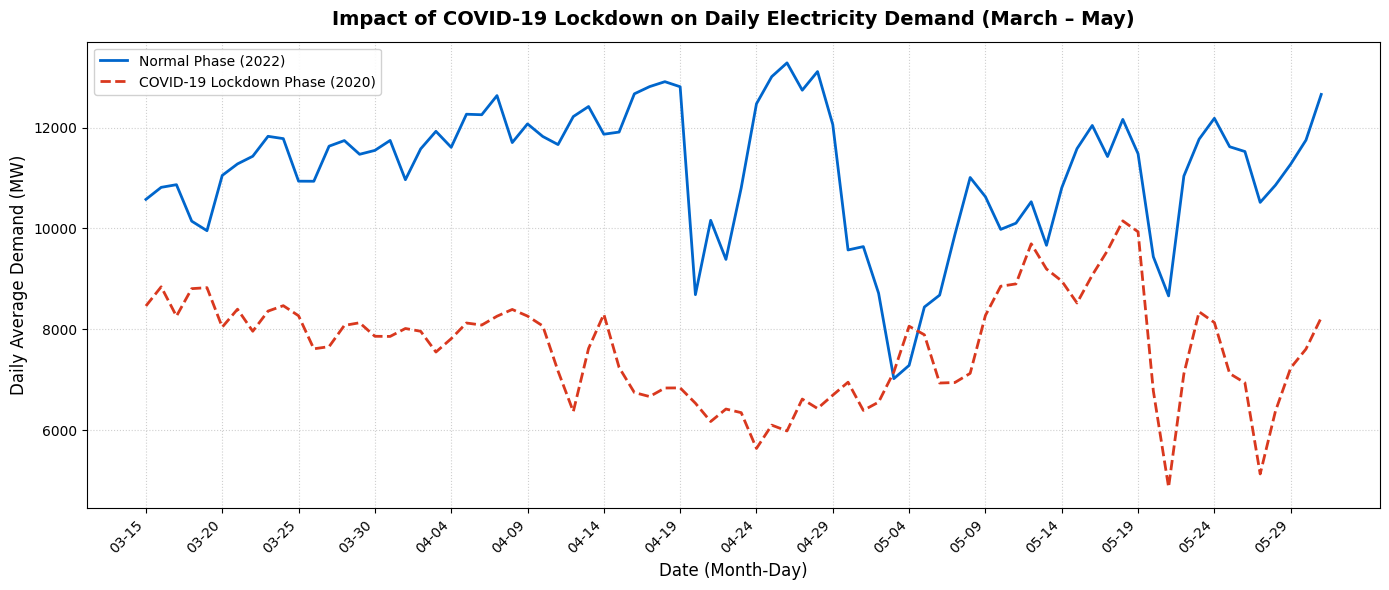

In [ ]:

# 1. Extract March 15 to May 31 for Normal Phase (2022) and COVID Lockdown Phase (2020)
mask_2022 = (df['datetime'] >= '2022-03-15') & (df['datetime'] <= '2022-05-31')
mask_2020 = (df['datetime'] >= '2020-03-15') & (df['datetime'] <= '2020-05-31')

df_normal = df[mask_2022].set_index('datetime')['demand_mw'].resample('D').mean().reset_index()
df_covid  = df[mask_2020].set_index('datetime')['demand_mw'].resample('D').mean().reset_index()

# 2. Extract day/month matching sequence for side-by-side alignment
df_normal['day_month'] = df_normal['datetime'].dt.strftime('%m-%d')
df_covid['day_month']  = df_covid['datetime'].dt.strftime('%m-%d')

# Merge on matching day-month calendar dates
df_compare = pd.merge(df_normal, df_covid, on='day_month', suffixes=('_normal', '_covid'))

# 3. Plot Comparison
plt.figure(figsize=(14, 6))

plt.plot(df_compare['day_month'], df_compare['demand_mw_normal'], color='#0066CC', linewidth=2.0, label='Normal Phase (2022)')
plt.plot(df_compare['day_month'], df_compare['demand_mw_covid'], color='#D9381E', linewidth=2.0, linestyle='--', label='COVID-19 Lockdown Phase (2020)')

# Formatting plot aesthetics
plt.title("Impact of COVID-19 Lockdown on Daily Electricity Demand (March – May)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Date (Month-Day)", fontsize=12)
plt.ylabel("Daily Average Demand (MW)", fontsize=12)
plt.xticks(df_compare['day_month'][::5], rotation=45, ha='right')  # Show every 5th date for clarity
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

Following the implementation of nationwide COVID-19 lockdowns in late March 2020, daily grid demand dropped sharply compared to the same period in 2022 due to the full shutdown of industrial factories and commercial office buildings. The lockdown phase reduced baseline consumption by roughly 1,500–2,500 MW, illustrating the impact of external structural shocks on national power generation.

# 2: Data Cleaning & Preprocessing

In [ ]:
# 2.1 Remove Duplicates
df = df.drop_duplicates()

# 2.2 Drop Generation/Import/Text Columns
drop_cols = [
'remarks', 'generation_mw', 'load_shedding', 'gas', 'liquid_fuel',
'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc',
'india_tripura', 'india_adani', 'nepal'
]

# Drop only columns that exist in df to prevent KeyErrors
existing_drop_cols = [col for col in drop_cols if col in df.columns]
df = df.drop(columns=existing_drop_cols)

# 2.3 Chronological Sorting
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

# 2.4 Outlier Removal using Interquartile Range (IQR) on target (demand_mw)
Q1 = df['demand_mw'].quantile(0.25)
Q3 = df['demand_mw'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df['demand_mw'] >= lower_bound) & (df['demand_mw'] <= upper_bound)].reset_index(drop=True)

# 2.5 Verification Summary
print("--- Cleaning Summary ---")
print(f"IQR Bounds for demand_mw: {lower_bound:.2f} MW to {upper_bound:.2f} MW")
print(f"Cleaned Dataset Shape:    {df.shape}")

print("\n--- Target Statistics (demand_mw) ---")
print(df['demand_mw'].describe())

--- Cleaning Summary ---
IQR Bounds for demand_mw: 1086.00 MW to 16366.00 MW
Cleaned Dataset Shape:    (92394, 2)

--- Target Statistics (demand_mw) ---
count    92394.000000
mean      8810.417311
std       2606.850478
min       1156.000000
25%       6816.000000
50%       8424.000000
75%      10630.000000
max      16350.000000
Name: demand_mw, dtype: float64


# 3: Feature Engineering

## Import Weather data

In [ ]:
# Open-Meteo API for Dhaka weather (2015-2025)
url = (
    "https://archive-api.open-meteo.com/v1/archive?"
    "latitude=23.8103&longitude=90.4125&"
    "start_date=2015-04-01&end_date=2025-06-30&"
    "hourly=temperature_2m,relative_humidity_2m,apparent_temperature,rain&"
    "timezone=Asia%2FDhaka"
)

print("Fetching weather data from Open-Meteo...")
response = requests.get(url)
data = response.json()

# Parse hourly JSON data to DataFrame
hourly_data = data['hourly']
df_weather = pd.DataFrame({
    'datetime': pd.to_datetime(hourly_data['time']),
    'temperature_c': hourly_data['temperature_2m'],
    'humidity_pct': hourly_data['relative_humidity_2m'],
    'feels_like_c': hourly_data['apparent_temperature'],
    'rain_mm': hourly_data['rain']
})

# Save locally to CSV
df_weather.to_csv('dhaka_weather_2015_2025.csv', index=False)
print("Saved weather data to 'dhaka_weather_2015_2025.csv'!")

Fetching weather data from Open-Meteo...
Saved weather data to 'dhaka_weather_2015_2025.csv'!


## Data Fusion

In [ ]:
# 3.1 Load & Merge Weather Data
df_weather = pd.read_csv('dhaka_weather_2015_2025.csv')
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])

# Merge PGCB df with Weather df on 'datetime'
df = pd.merge(df, df_weather, on='datetime', how='inner')

# 3.2 Time & Calendar Features
df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['is_weekend'] = df['dayofweek'].isin([4, 5]).astype(int) # Fri=4, Sat=5 (Bangladesh)

# Peak Period Indicators (Bangladesh Grid Context)
df['is_day_peak'] = df['hour'].between(10, 17).astype(int) # 10:00 AM - 5:00 PM
df['is_evening_peak'] = df['hour'].between(17, 23).astype(int) # 5:00 PM - 11:00 PM

# 3.3 Public Holidays
fixed_holidays = [
  (2, 21), (3, 17), (3, 26), (4, 14),
  (5, 1), (8, 15), (12, 16), (12, 25)
]

df['is_holiday'] = df['datetime'].apply(
  lambda dt: 1 if (dt.month, dt.day) in fixed_holidays else 0
)

# 3.4 Target Lags
df['demand_lag_1h'] = df['demand_mw'].shift(1)
df['demand_lag_3h'] = df['demand_mw'].shift(3)
df['demand_lag_6h'] = df['demand_mw'].shift(6)
df['demand_lag_24h'] = df['demand_mw'].shift(24)
df['demand_lag_168h'] = df['demand_mw'].shift(168)

# 3.5 Rolling Statistics (Shifted by 1 to prevent data leakage)
for window in [2, 6, 3, 24]:
  df[f'demand_rolling_mean_{window}h'] = df['demand_mw'].shift(1).rolling(window=window).mean()
  df[f'demand_rolling_max_{window}h'] = df['demand_mw'].shift(1).rolling(window=window).max()
  df[f'demand_rolling_min_{window}h'] = df['demand_mw'].shift(1).rolling(window=window).min()

# 3.6 Drop NaN rows created by Lagging / Rolling operations
df = df.dropna().reset_index(drop=True)

# 3.7 Output Summary
print("--- Section 3 Summary ---")
print(f"Final Dataset Shape: {df.shape}")
print(f"All Columns ({len(df.columns)}): {df.columns.tolist()}")
print("\n--- First 5 Rows ---")
print(df.head())


--- Section 3 Summary ---
Final Dataset Shape: (88064, 30)
All Columns (30): ['datetime', 'demand_mw', 'temperature_c', 'humidity_pct', 'feels_like_c', 'rain_mm', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_day_peak', 'is_evening_peak', 'is_holiday', 'demand_lag_1h', 'demand_lag_3h', 'demand_lag_6h', 'demand_lag_24h', 'demand_lag_168h', 'demand_rolling_mean_2h', 'demand_rolling_max_2h', 'demand_rolling_min_2h', 'demand_rolling_mean_6h', 'demand_rolling_max_6h', 'demand_rolling_min_6h', 'demand_rolling_mean_3h', 'demand_rolling_max_3h', 'demand_rolling_min_3h', 'demand_rolling_mean_24h', 'demand_rolling_max_24h', 'demand_rolling_min_24h']

--- First 5 Rows ---
             datetime  demand_mw  temperature_c  humidity_pct  feels_like_c  rain_mm  hour  dayofweek  month  is_weekend  is_day_peak  is_evening_peak  is_holiday  demand_lag_1h  demand_lag_3h  demand_lag_6h  demand_lag_24h  demand_lag_168h  demand_rolling_mean_2h  demand_rolling_max_2h  demand_rolling_min_2h  demand_rolling_m

## Post-Feature Engineering EDA

In [ ]:
# 1. Check missing values across all columns
print("--- Missing Values per Column ---")
print(df.isnull().sum())
print(f"\nTotal Dataset NaN Count: {df.isnull().sum().sum()}\n")

# 2. Categorical & Binary Distributions
print("--- Weekend Count (0 = Weekday, 1 = Weekend) ---")
print(df['is_weekend'].value_counts())

print("\n--- Holiday Count (0 = Regular Day, 1 = Holiday) ---")
print(df['is_holiday'].value_counts())

# 3. Summary Statistics for ALL Features
print("\n--- Summary Statistics (All Numeric Features) ---")
print(df.describe().T)

--- Missing Values per Column ---
datetime                   0
demand_mw                  0
temperature_c              0
humidity_pct               0
feels_like_c               0
rain_mm                    0
hour                       0
dayofweek                  0
month                      0
is_weekend                 0
is_day_peak                0
is_evening_peak            0
is_holiday                 0
demand_lag_1h              0
demand_lag_3h              0
demand_lag_6h              0
demand_lag_24h             0
demand_lag_168h            0
demand_rolling_mean_2h     0
demand_rolling_max_2h      0
demand_rolling_min_2h      0
demand_rolling_mean_6h     0
demand_rolling_max_6h      0
demand_rolling_min_6h      0
demand_rolling_mean_3h     0
demand_rolling_max_3h      0
demand_rolling_min_3h      0
demand_rolling_mean_24h    0
demand_rolling_max_24h     0
demand_rolling_min_24h     0
dtype: int64

Total Dataset NaN Count: 0

--- Weekend Count (0 = Weekday, 1 = Weekend) ---
is_we

# 5: Train-Test Split

In [ ]:
# Date-Based Train / Validation / Test Split
train_end = '2023-12-31 23:00:00'
val_end = '2024-06-30 23:00:00'

# 1. Split raw dataframes chronologically
train_df = df[df['datetime'] <= train_end].copy()
val_df = df[(df['datetime'] > train_end) & (df['datetime'] <= val_end)].copy()
test_df = df[df['datetime'] > val_end].copy()

# 2. Define features for Tabular Models (Trees/MLP)
feature_cols = [
# Weather Features
'temperature_c', 'humidity_pct',

# Time & Peak Features
'hour', 'dayofweek', 'month', 'is_weekend', 'is_holiday',
'is_day_peak', 'is_evening_peak',

# Target Lags
'demand_lag_1h', 'demand_lag_3h','demand_lag_6h', 'demand_lag_24h', 'demand_lag_168h',

# 2h Rolling Statistics
'demand_rolling_mean_2h',
'demand_rolling_max_2h',
'demand_rolling_min_2h',

# 6h Rolling Statistics
'demand_rolling_mean_6h',
'demand_rolling_max_6h',
'demand_rolling_min_6h',

# 3h Rolling Statistics
'demand_rolling_mean_3h',
'demand_rolling_max_3h',
'demand_rolling_min_3h',

# 24h Rolling Statistics
'demand_rolling_mean_24h',
'demand_rolling_max_24h',
'demand_rolling_min_24h'
]
target_col = 'demand_mw'

# 3. Form Tabular Feature Matrices
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print(f"Train Set: {X_train.shape} | Val Set: {X_val.shape} | Test Set: {X_test.shape}")
print(f"Total Features: {len(feature_cols)}")

Train Set: (75327, 26) | Val Set: (4312, 26) | Test Set: (8425, 26)
Total Features: 26


# Spearman Correlation

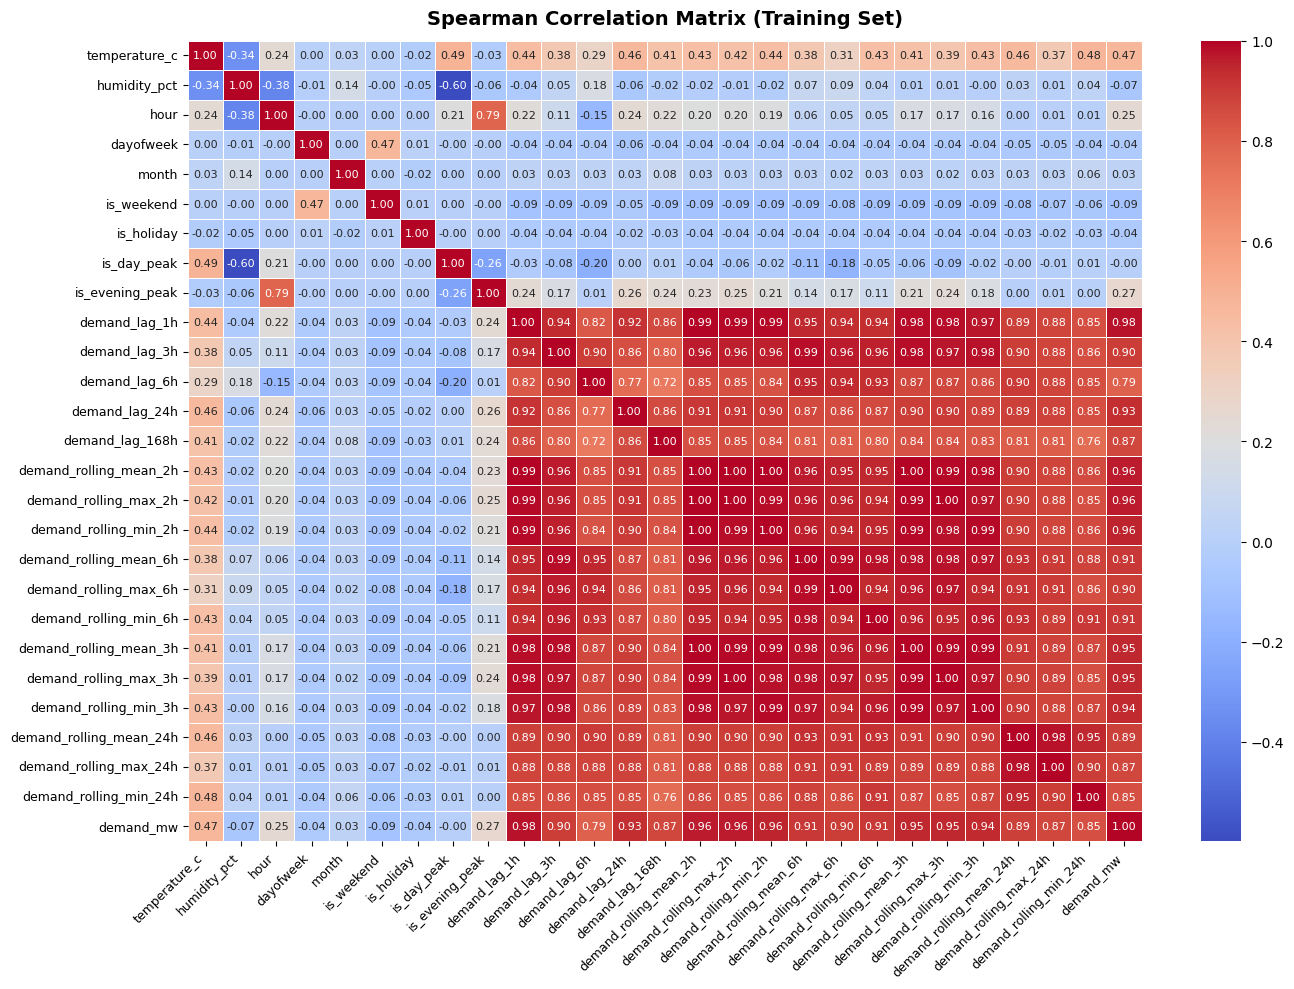

       SPEARMAN FEATURE PRUNING SUMMARY
Original Feature Count : 26
Pruned Feature Count   : 16
Dropped Features Count : 10

--- Dropped Redundant Features (|r_s| > 0.95) ---
  • demand_lag_3h
  • demand_rolling_max_24h
  • demand_rolling_max_2h
  • demand_rolling_max_3h
  • demand_rolling_max_6h
  • demand_rolling_mean_2h
  • demand_rolling_mean_3h
  • demand_rolling_min_2h
  • demand_rolling_min_3h
  • demand_rolling_min_6h

Updated Matrices -> X_train: (75327, 16) | X_val: (4312, 16) | X_test: (8425, 16)


In [ ]:
# ==============================================================================
# EXPERIMENTAL CELL: Spearman Multicollinearity Feature Selection + Heatmap
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Start from your manually defined feature set
candidate_cols = feature_cols.copy()

# 2. Compute Spearman correlation matrix ONLY on train_df (prevents data leakage)
train_corr = train_df[candidate_cols + [target_col]].corr(method='spearman')
abs_train_corr = train_corr.abs()

# 3. Plot Spearman Correlation Heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    train_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar=True,
    annot_kws={"size": 8}
)
plt.title("Spearman Correlation Matrix (Training Set)", fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

# 4. Extract feature-to-feature matrix (excluding target)
feat_corr = abs_train_corr.loc[candidate_cols, candidate_cols]

# 5. Identify feature pairs with Spearman correlation > threshold (e.g., 0.95)
upper_tri = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
threshold = 0.95

dropped_cols = set()
for col in upper_tri.columns:
    # Find features highly correlated with 'col'
    high_corr_feats = upper_tri.index[upper_tri[col] > threshold].tolist()

    for feat in high_corr_feats:
        if feat not in dropped_cols and col not in dropped_cols:
            # Check which feature has higher correlation with target (demand_mw)
            corr_feat_target = abs_train_corr.loc[feat, target_col]
            corr_col_target = abs_train_corr.loc[col, target_col]

            # Keep the stronger feature, mark the weaker one for removal
            if corr_feat_target < corr_col_target:
                dropped_cols.add(feat)
            else:
                dropped_cols.add(col)

# 6. Form the pruned feature list
pruned_feature_cols = [c for c in candidate_cols if c not in dropped_cols]

# 7. Print summary with dropped columns displayed vertically
print("=" * 55)
print("       SPEARMAN FEATURE PRUNING SUMMARY")
print("=" * 55)
print(f"Original Feature Count : {len(candidate_cols)}")
print(f"Pruned Feature Count   : {len(pruned_feature_cols)}")
print(f"Dropped Features Count : {len(dropped_cols)}")

print("\n--- Dropped Redundant Features (|r_s| > 0.95) ---")
if dropped_cols:
    for col in sorted(dropped_cols):
        print(f"  • {col}")
else:
    print("  None (No feature pairs exceeded the threshold)")

print("=" * 55)

# ==============================================================================
# OVERWRITE MATRICES (Model variable names remain 100% identical downstream)
# ==============================================================================
X_train = train_df[pruned_feature_cols]
X_val   = val_df[pruned_feature_cols]
X_test  = test_df[pruned_feature_cols]

print(f"\nUpdated Matrices -> X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

# 6: Model training

In [ ]:
import time

def get_metrics(y_true, y_pred, model_name, train_time=None, infer_time=None):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    medae = median_absolute_error(y_true, y_pred)
    max_err = max_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"=== {model_name} Performance ===")
    print(f"MAE           : {mae:.2f} MW")
    print(f"RMSE          : {rmse:.2f} MW")
    print(f"MAPE          : {mape:.2f}%")
    print(f"MedAE         : {medae:.2f} MW")
    print(f"Max Error     : {max_err:.2f} MW")
    print(f"R²            : {r2:.4f}")
    if train_time is not None:
        print(f"Train Time    : {train_time:.4f} sec")
    if infer_time is not None:
        print(f"Inference Time: {infer_time:.4f} sec")
    print()

    res = {
        'Model': model_name,
        'MAE (MW)': round(mae, 2),
        'RMSE (MW)': round(rmse, 2),
        'MAPE (%)': round(mape, 2),
        'MedAE (MW)': round(medae, 2),
        'Max Error (MW)': round(max_err, 2),
        'R2 Score': round(r2, 4)
    }

    if train_time is not None:
        res['Train Time (s)'] = round(train_time, 4)
    if infer_time is not None:
        res['Inference Time (s)'] = round(infer_time, 4)

    return res

# Dictionary to store results for comparison
model_results = {}

## Linear Regression

In [ ]:
# Linear Regression Model

# Initialize
lr_model = LinearRegression()

# Measure Train Time
start_train = time.perf_counter()
lr_model.fit(X_train, y_train)
train_time_lr = time.perf_counter() - start_train

# Measure Inference Time on Validation Set
start_infer = time.perf_counter()
y_pred_val_lr = lr_model.predict(X_val)
infer_time_lr = time.perf_counter() - start_infer

# Evaluate & Store Results
model_results['Linear Regression'] = get_metrics(
    y_val,
    y_pred_val_lr,
    "Linear Regression",
    train_time=train_time_lr,
    infer_time=infer_time_lr
)

=== Linear Regression Performance ===
MAE           : 373.22 MW
RMSE          : 699.34 MW
MAPE          : 4.46%
MedAE         : 270.37 MW
Max Error     : 13518.44 MW
R²            : 0.9260
Train Time    : 0.0605 sec
Inference Time: 0.0025 sec



## Random Forest

In [ ]:
# Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Measure Train Time
start_train = time.perf_counter()
rf_model.fit(X_train, y_train)
train_time_rf = time.perf_counter() - start_train

# Measure Inference Time on Validation Set
start_infer = time.perf_counter()
y_pred_rf = rf_model.predict(X_val)
infer_time_rf = time.perf_counter() - start_infer

# Evaluate on Validation Set
model_results['Random Forest'] = get_metrics(
    y_val,
    y_pred_rf,
    "Random Forest Regressor",
    train_time=train_time_rf,
    infer_time=infer_time_rf
)

=== Random Forest Regressor Performance ===
MAE           : 282.93 MW
RMSE          : 587.07 MW
MAPE          : 3.43%
MedAE         : 177.56 MW
Max Error     : 13428.70 MW
R²            : 0.9478
Train Time    : 82.7877 sec
Inference Time: 0.0936 sec



Advanced Models

## LightGBM Regressor

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011792 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2176
[LightGBM] [Info] Number of data points in the train set: 75327, number of used features: 16
[LightGBM] [Info] Start training from score 8321.779800
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

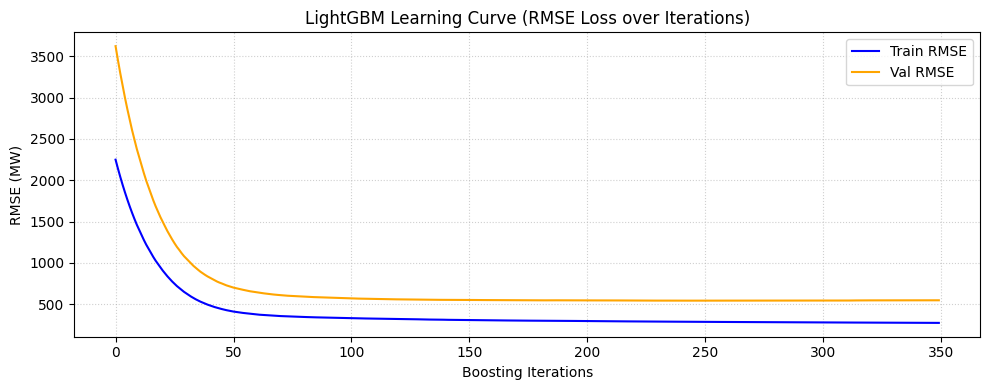

In [ ]:
# LightGBM Regressor

# 1. Define Model
lgb_model = LGBMRegressor(
    n_estimators=350,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# 2. Train Model with Validation Set tracking & Measure Train Time
start_train = time.perf_counter()
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    eval_names=['Train', 'Val'],
    eval_metric='rmse'
)
train_time_lgb = time.perf_counter() - start_train

# 3. Predict & Measure Inference Time on Validation Set
start_infer = time.perf_counter()
y_pred_lgb = lgb_model.predict(X_val)
infer_time_lgb = time.perf_counter() - start_infer

# 4. Evaluate & Store Results
model_results['LightGBM'] = get_metrics(
    y_val,
    y_pred_lgb,
    "LightGBM Regressor",
    train_time=train_time_lgb,
    infer_time=infer_time_lgb
)

# 5. Plot Learning Curve (RMSE Loss)
lgb_results = lgb_model.evals_result_
plt.figure(figsize=(10, 4))
plt.plot(lgb_results['Train']['rmse'], label='Train RMSE', color='blue')
plt.plot(lgb_results['Val']['rmse'], label='Val RMSE', color='orange')
plt.title("LightGBM Learning Curve (RMSE Loss over Iterations)")
plt.xlabel("Boosting Iterations")
plt.ylabel("RMSE (MW)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## XGBoost Regressor

=== XGBoost Regressor Performance ===
MAE           : 338.09 MW
RMSE          : 658.76 MW
MAPE          : 3.75%
MedAE         : 193.03 MW
Max Error     : 13172.15 MW
R²            : 0.9343
Train Time    : 3.4792 sec
Inference Time: 0.0333 sec



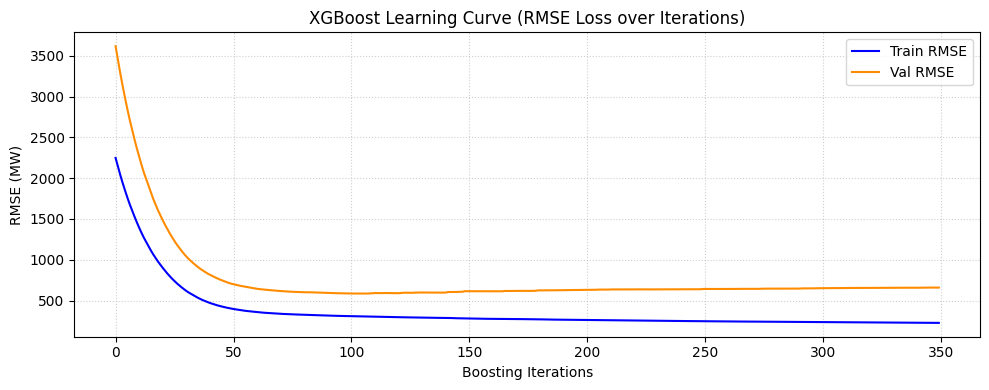

In [ ]:
# XGBoost Regressor

# 1. Define Model
xgb_model = XGBRegressor(
    n_estimators=350,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# 2. Train Model with Validation Set tracking & Measure Train Time
start_train = time.perf_counter()
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)
train_time_xgb = time.perf_counter() - start_train

# 3. Predict & Measure Inference Time on Validation Set
start_infer = time.perf_counter()
y_pred_xgb = xgb_model.predict(X_val)
infer_time_xgb = time.perf_counter() - start_infer

# 4. Evaluate & Store Results
model_results['XGBoost'] = get_metrics(
    y_val,
    y_pred_xgb,
    "XGBoost Regressor",
    train_time=train_time_xgb,
    infer_time=infer_time_xgb
)

# 4. Plot Learning Curve (RMSE Loss)
xgb_results = xgb_model.evals_result()
plt.figure(figsize=(10, 4))
plt.plot(xgb_results['validation_0']['rmse'], label='Train RMSE', color='blue')
plt.plot(xgb_results['validation_1']['rmse'], label='Val RMSE', color='darkorange')
plt.title("XGBoost Learning Curve (RMSE Loss over Iterations)")
plt.xlabel("Boosting Iterations")
plt.ylabel("RMSE (MW)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Neural Network MLP

In [ ]:
# Multilayer Perceptron (MLP)

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Feature Selection & Reshaping
X_train_raw = X_train.values
y_train_raw = y_train.values.reshape(-1, 1)

X_val_raw = X_val.values
y_val_raw = y_val.values.reshape(-1, 1)

# Pre-fit scalers & prepare transformed sets
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_tr = scaler_X.fit_transform(X_train_raw)
y_tr = scaler_y.fit_transform(y_train_raw)
X_va = scaler_X.transform(X_val_raw)
y_va = scaler_y.transform(y_val_raw)

# 2. Build Keras MLP Model
mlp_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_tr.shape[1],)),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1)
])

mlp_model.compile(optimizer='adam', loss='mse')

# 3. Measure Training Time
start_train = time.perf_counter()
history = mlp_model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=20,
    batch_size=64,
    verbose=1
)
train_time_mlp = time.perf_counter() - start_train

# 4. Measure Inference Time on Validation Set
start_infer = time.perf_counter()
y_pred_scaled = mlp_model.predict(X_va)
y_pred_mlp = scaler_y.inverse_transform(y_pred_scaled).flatten()
infer_time_mlp = time.perf_counter() - start_infer

# 5. Log Metrics
model_results['MLP'] = get_metrics(
    y_val,
    y_pred_mlp,
    "MLP Regressor",
    train_time=train_time_mlp,
    infer_time=infer_time_mlp
)
print("MLP Training & Evaluation Complete!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0578 - val_loss: 0.0813
Epoch 2/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0336 - val_loss: 0.0921
Epoch 3/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0292 - val_loss: 0.0978
Epoch 4/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0274 - val_loss: 0.0811
Epoch 5/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0263 - val_loss: 0.0839
Epoch 6/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0248 - val_loss: 0.0757
Epoch 7/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0238 - val_loss: 0.0811
Epoch 8/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0233 - val_loss: 0.0894
Epoch 9/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0230 - val_loss: 0.1035
Epoch 10/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0224 - val_loss: 0.0954
Epoch 11/20
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0220 - val_loss: 0.1030
Epoch 12/20
1177/1177 ━━━━━━━━

# 7: Final Comparison

In [ ]:
# Comprehensive Model Summary & Best Model Selection

# 1. Convert results to DataFrame and sort by R2 Score (descending)
df_all_models = pd.DataFrame(list(model_results.values()))
df_all_models = df_all_models.sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("=========================================================================================================")
print("                                   COMPLETE MODEL PERFORMANCE TABLE                                      ")
print("=========================================================================================================")
print(df_all_models.to_string(index=False))
print("=========================================================================================================\n")

# 2. Automatically Select Best Model (Highest R2, Lowest MAPE)
best_model_row = df_all_models.iloc[0] # Already sorted by highest R2 Score
best_model_name = best_model_row['Model']

print(f"🏆 Selected Best Model : {best_model_name}")
print(f"Validation R² Score    : {best_model_row['R2 Score']}")
print(f"Validation MAE         : {best_model_row['MAE (MW)']} MW")
print(f"Validation MAPE        : {best_model_row['MAPE (%)']}%")

if 'Train Time (s)' in best_model_row:
    print(f"Training Time          : {best_model_row['Train Time (s)']} sec")
if 'Inference Time (s)' in best_model_row:
    print(f"Inference Time         : {best_model_row['Inference Time (s)']} sec")

                                   COMPLETE MODEL PERFORMANCE TABLE                                      
                  Model  MAE (MW)  RMSE (MW)  MAPE (%)  MedAE (MW)  Max Error (MW)  R2 Score  Train Time (s)  Inference Time (s)
     LightGBM Regressor    282.16     548.98      3.36      194.22        13345.87    0.9544          2.5004              0.0659
Random Forest Regressor    282.93     587.07      3.43      177.56        13428.70    0.9478         82.7877              0.0936
      XGBoost Regressor    338.09     658.76      3.75      193.03        13172.15    0.9343          3.4792              0.0333
      Linear Regression    373.22     699.34      4.46      270.37        13518.44    0.9260          0.0605              0.0025
          MLP Regressor    658.87     908.39      6.15      498.62        12250.97    0.8751         83.2218              0.3897

🏆 Selected Best Model : LightGBM Regressor
Validation R² Score    : 0.9544
Validation MAE         : 282.16 MW
Validatio

# 8: Hypertuning

In [ ]:
# LightGBM Hyperparameter Fine-Tuning

print("Starting Fine-Tuning for LightGBM...")

# 1. Base Model Configuration
base_lgb = LGBMRegressor(
    random_state=42,
    n_jobs=-1
)

# 2. Targeted Fine-Tuning Search Space
param_distributions = {
    'n_estimators': randint(150, 350),
    'learning_rate': uniform(0.02, 0.06),
    'num_leaves': randint(20, 50),
    'max_depth': [5, 6, 7, 8, 10],
    'subsample': uniform(0.8, 0.2),
    'colsample_bytree': uniform(0.8, 0.2),
    'reg_alpha': uniform(0.0, 0.5),
    'reg_lambda': uniform(0.0, 0.5)
}

# 3. TimeSeriesSplit Cross-Validation (Preserves time order)
tscv = TimeSeriesSplit(n_splits=3)

# 4. Randomized Search with 8 Iterations
random_search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_distributions,
    n_iter=8,
    cv=tscv,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Measure Search / Fine-Tuning Time
start_tune = time.perf_counter()
random_search.fit(X_train, y_train)
tune_time_lgb = time.perf_counter() - start_tune

# 5. Extract Fine-Tuned Model
tuned_lgb_model = random_search.best_estimator_

print("\n=== Fine-Tuning Complete ===")
print(f"Total Fine-Tuning Time: {tune_time_lgb:.2f} sec")
print("Best Hyperparameters Found:")

for k, v in random_search.best_params_.items():
    print(f"  • {k}: {v}")

# 6. Measure Inference Time & Evaluate on Validation Set
start_infer = time.perf_counter()
y_pred_val_tuned = tuned_lgb_model.predict(X_val)
infer_time_tuned_lgb = time.perf_counter() - start_infer

model_results['LightGBM (Tuned)'] = get_metrics(
    y_val,
    y_pred_val_tuned,
    "LightGBM Regressor (Tuned)",
    train_time=tune_time_lgb,
    infer_time=infer_time_tuned_lgb
)

# 7. Update Model References for Cell 8.6
model_dict = {}
best_model_name = 'LightGBM Regressor (Tuned)'
model_dict['LightGBM Regressor (Tuned)'] = tuned_lgb_model

Starting Fine-Tuning for LightGBM...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.046926 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2176
[LightGBM] [Info] Number of data points in the train set: 75327, number of used features: 16
[LightGBM] [Info] Start training from score 8321.779800
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with 

# 8: Final Evaluation on Test Set

In [ ]:
# 1. Map model names to trained objects
model_dict = {
    'Linear Regression': lr_model,
    'Random Forest Regressor': rf_model,
    'LightGBM Regressor': lgb_model,
    'XGBoost Regressor': xgb_model,
    'MLP Regressor': mlp_model,
    'LightGBM Regressor (Tuned)': tuned_lgb_model
}

# 2. Retrieve winning model
best_model = model_dict[best_model_name]

# 3. Predict on Test Set & Measure Test Inference Time
start_test_infer = time.perf_counter()

if best_model_name == 'MLP Regressor':
    X_test_scaled = scaler_X.transform(X_test.values)
    y_pred_scaled = best_model.predict(X_test_scaled)
    y_pred_test = scaler_y.inverse_transform(y_pred_scaled).flatten()
else:
    y_pred_test = best_model.predict(X_test)

test_infer_time = time.perf_counter() - start_test_infer

# 4. Final Performance Report on Test Set
print("==========================================================================")
print(f"               FINAL TEST SET PERFORMANCE ({best_model_name})             ")
print("==========================================================================")
final_test_metrics = get_metrics(
    y_test,
    y_pred_test,
    f"Final Test - {best_model_name}",
    infer_time=test_infer_time
)

               FINAL TEST SET PERFORMANCE (LightGBM Regressor (Tuned))             
=== Final Test - LightGBM Regressor (Tuned) Performance ===
MAE           : 241.89 MW
RMSE          : 353.13 MW
MAPE          : 2.14%
MedAE         : 173.32 MW
Max Error     : 10784.94 MW
R²            : 0.9740
Inference Time: 0.1120 sec



# 9: Feature Importance (SHAP & Gain)

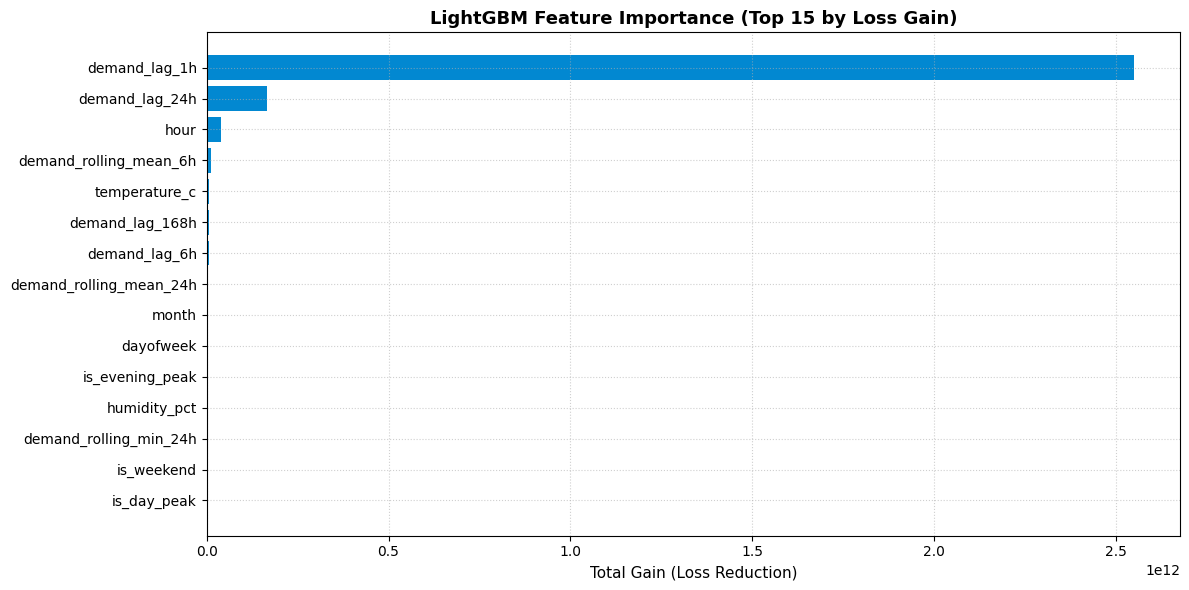

Computing SHAP values for Test Set...


/tmp/ipykernel_579/2746047702.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, max_display=15, show=False)


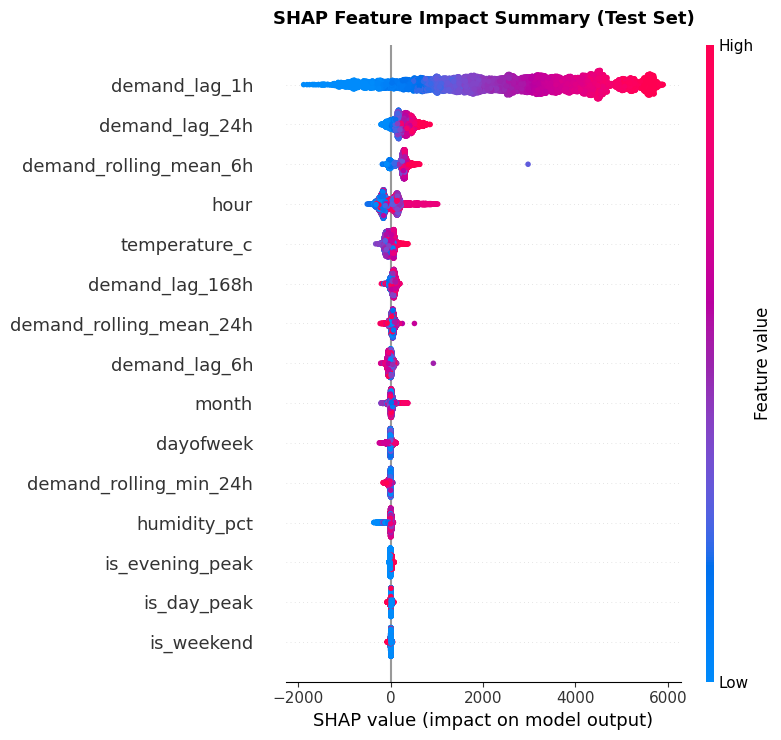

In [ ]:
# 1. LightGBM Built-in Feature Importance (Gain)
feature_names = X_train.columns
importances = tuned_lgb_model.booster_.feature_importance(importance_type='gain')

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance_Gain': importances
}).sort_values('Importance_Gain', ascending=False)

# Plot Top 15 Built-in Features
plt.figure(figsize=(12, 6))
plt.barh(df_importance['Feature'].head(15)[::-1], df_importance['Importance_Gain'].head(15)[::-1], color='#0288D1')
plt.title("LightGBM Feature Importance (Top 15 by Loss Gain)", fontsize=13, fontweight='bold')
plt.xlabel("Total Gain (Loss Reduction)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. SHAP Analysis (Directional & Global Impact)
print("Computing SHAP values for Test Set...")
explainer = shap.TreeExplainer(tuned_lgb_model)
shap_values = explainer(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, max_display=15, show=False)
plt.title("SHAP Feature Impact Summary (Test Set)", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 10: Visualizations & Diagnostic Plots

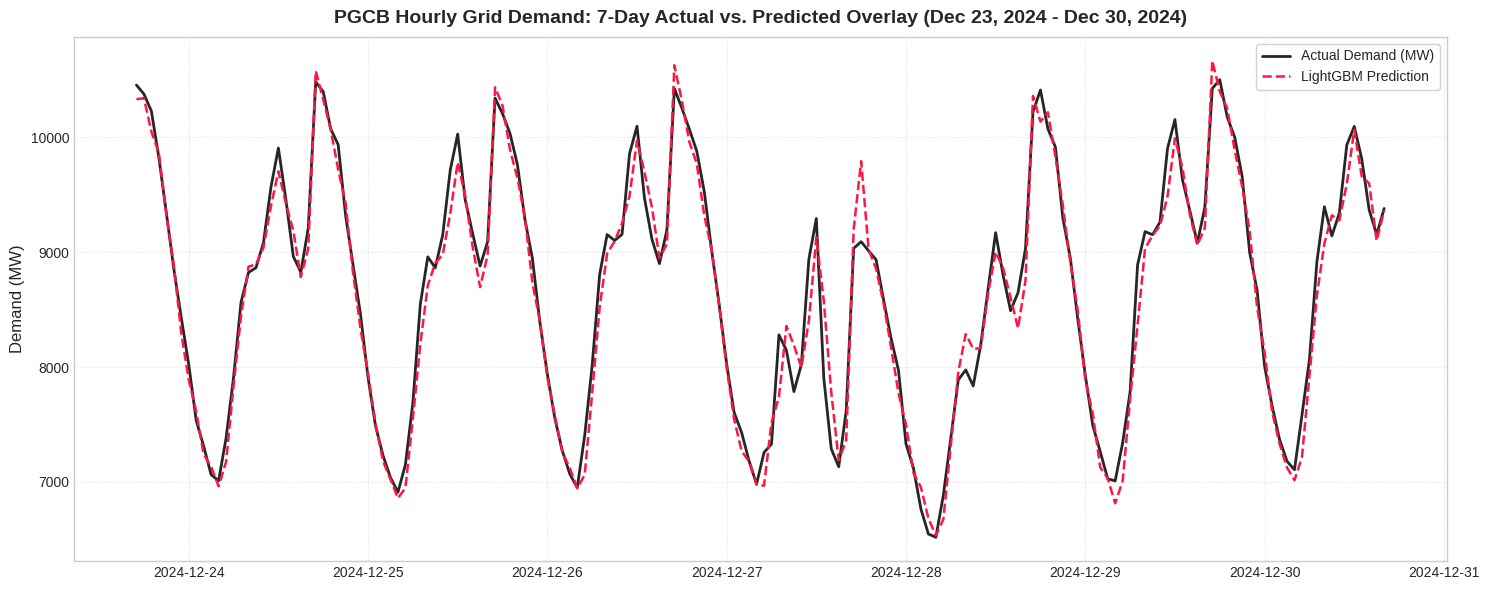

In [ ]:

# Set aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 1, figsize=(15, 6)) # Changed to 1 subplot

# Select the winning model instance
active_model = tuned_lgb_model if 'tuned_lgb_model' in globals() else lgb_model

# ------------------------------------------
# Plot 1: 7-Day Actual vs Predicted Timeline (Mid-Test Set Timeline)
# ------------------------------------------
sample_hours = 168  # 7 days * 24 hours

# Select a 7-day window from the middle of the Test dataset
mid_start = len(test_df) // 2
mid_end = mid_start + sample_hours

sample_df = test_df.iloc[mid_start:mid_end].copy()
sample_X = X_test.iloc[mid_start:mid_end]

# Generate predictions for the sampled timeline
sample_df['pred_lgb'] = active_model.predict(sample_X)

# Plot Time Series Overlay
axes.plot(sample_df['datetime'], sample_df['demand_mw'], label='Actual Demand (MW)', color='black', linewidth=2, alpha=0.85)
axes.plot(sample_df['datetime'], sample_df['pred_lgb'], label='LightGBM Prediction', color='#FF1744', linestyle='--', linewidth=1.8)

# Format Title with Dynamic Start and End Dates
start_date_str = pd.to_datetime(sample_df['datetime'].iloc[0]).strftime('%b %d, %Y')
end_date_str = pd.to_datetime(sample_df['datetime'].iloc[-1]).strftime('%b %d, %Y')

axes.set_title(f'PGCB Hourly Grid Demand: 7-Day Actual vs. Predicted Overlay ({start_date_str} - {end_date_str})', fontsize=14, fontweight='bold', pad=10)
axes.set_ylabel('Demand (MW)', fontsize=12)
axes.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
axes.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

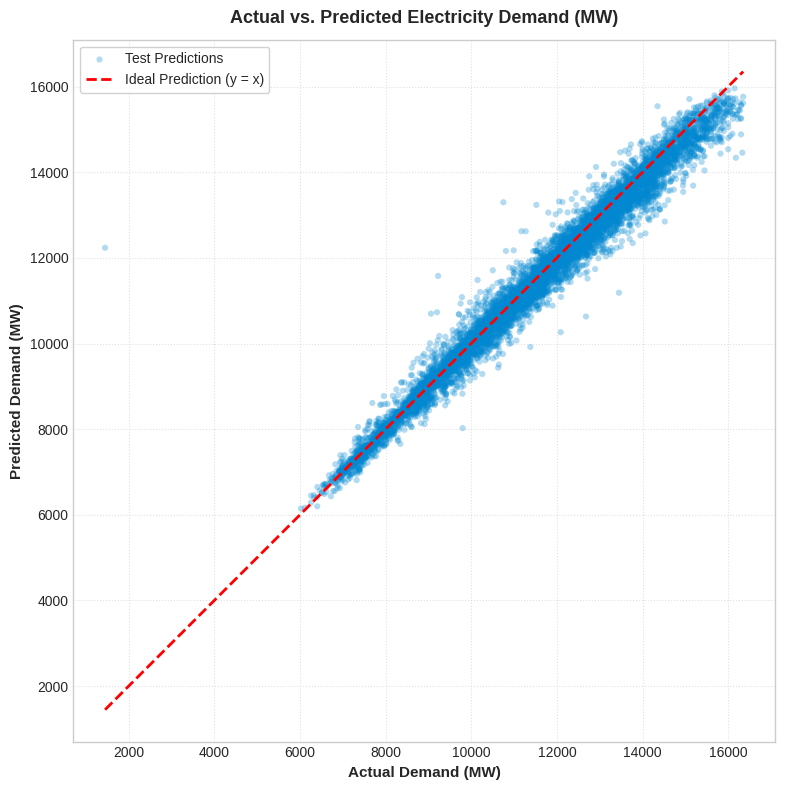

In [ ]:
# ==========================================
# Actual vs. Predicted Demand Scatter Plot
# ==========================================


# Select active best model predictions
y_pred_active = tuned_lgb_model.predict(X_test) if 'tuned_lgb_model' in globals() else lgb_model.predict(X_test)

plt.figure(figsize=(9, 8))

# Scatter plot of actual vs predicted
plt.scatter(y_test, y_pred_active, alpha=0.3, color='#0288D1', edgecolors='none', s=20, label='Test Predictions')

# Perfect prediction reference line (y = x)
min_val = min(y_test.min(), y_pred_active.min())
max_val = max(y_test.max(), y_pred_active.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Prediction (y = x)')

# Formatting
plt.title("Actual vs. Predicted Electricity Demand (MW)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Actual Demand (MW)", fontsize=11, fontweight='bold')
plt.ylabel("Predicted Demand (MW)", fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# Equal aspect ratio for accurate diagonal perspective
plt.gca().set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Cell: Extreme Peak & Load-Shedding Risk Analysis
# ==========================================

# Calculate point-by-point absolute forecast errors
test_analysis = test_df.copy()
active_model = tuned_lgb_model if 'tuned_lgb_model' in globals() else lgb_model
test_analysis['pred_mw'] = active_model.predict(X_test)
test_analysis['error_mw'] = test_analysis['demand_mw'] - test_analysis['pred_mw']
test_analysis['abs_error_mw'] = np.abs(test_analysis['error_mw'])

# 1. Quantify Under-prediction Risk (Grid Vulnerability)
under_predictions = test_analysis[test_analysis['error_mw'] > 0]
max_underpred = under_predictions['error_mw'].max()
p95_error = np.percentile(test_analysis['abs_error_mw'], 95)

print("=== GRID RELIABILITY & ERROR EXTREMES ===")
print(f"95th Percentile Error Bound : {p95_error:.2f} MW (95% of predictions are within this error margin)")
print(f"Maximum Under-prediction    : {max_underpred:.2f} MW (Worst-case supply shortfall risk)")
print(f"Mean Demand on Test Set     : {test_analysis['demand_mw'].mean():.2f} MW")
print(f"Overall MAE as % of Mean    : {(test_analysis['abs_error_mw'].mean() / test_analysis['demand_mw'].mean()) * 100:.2f}%")

=== GRID RELIABILITY & ERROR EXTREMES ===
95th Percentile Error Bound : 695.32 MW (95% of predictions are within this error margin)
Maximum Under-prediction    : 2263.69 MW (Worst-case supply shortfall risk)
Mean Demand on Test Set     : 11584.20 MW
Overall MAE as % of Mean    : 2.09%
